# Introducción a la Ciencia de Datos 2026

César Eduardo Jardines Mendoza Cuatrimestre III-2026 CICESE

# Tarea: CNN compacta con *Global Average Pooling* en MNIST

En la sesión 21 del curso vimos que una CNN con Flatten llega a casi 97 % de exactitud en validación, pero cuando movemos el dígito unos cuantos píxeles su exactitud se desploma. La misma red con Global Average Pooling (GAP) casi no cambia al mover el dígito, pero solo acierta en menos de la mitad de las imágenes.

En esta tarea vamos a buscar una CNN con GAP que cumpla dos requisitos:

1. Superar el **95 %** de exactitud en validación.
2. Usar menos de **54 330** parámetros entrenables, que es lo que usa la CNN base con Flatten.

Entre las arquitecturas que cumplan los dos, me voy a quedar con la que tenga menos parámetros. Después vamos a medir qué tan bien reconoce los dígitos cuando cambia su posición, y lo vamos a comparar con los dos modelos base.

## 1. Configuración

Como **primer paso** vamos a importar las librerías y a definir las mismas constantes del notebook del curso: la semilla, el tamaño de cada partición, el margen, el tamaño de lote, la tasa de aprendizaje y el número de épocas. Todas las variantes que entrenemos van a usar estos mismos valores, así que cualquier diferencia en exactitud se va a deber a la arquitectura y no a la configuración.

También imprimimos las versiones de las librerías. El notebook del curso se ejecutó en otro equipo y con otras versiones, por lo que las cifras pueden variar un poco en los últimos decimales.

In [1]:
import platform
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import train_test_split
from tensorflow import keras

# Mismas constantes del notebook del curso
SEMILLA = 42
N_ENT, N_VAL, N_PRUEBA = 8000, 1500, 2000
MARGEN = 4

# Configuración de entrenamiento, igual para todas las variantes
LOTE = 128
EPOCAS = 20
TASA = 0.001

# Quitamos los bordes de arriba y derecha de las gráficas, como en el curso
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# Imprimimos las versiones para que la ejecución se pueda reproducir
print(f"Python {platform.python_version()} · TensorFlow {tf.__version__} · Keras {keras.__version__}")
print(f"NumPy {np.__version__} · pandas {pd.__version__} · scikit-learn {sklearn.__version__}")

Python 3.13.18 · TensorFlow 2.21.0 · Keras 3.13.2
NumPy 2.4.6 · pandas 2.2.3 · scikit-learn 1.6.1


Como **segundo paso** vamos a cargar MNIST con las mismas particiones del notebook del curso. Esto es importante porque si cambiamos la partición, las exactitudes de validación ya no se podrían comparar con las de los modelos base.

La función `preparar_imagenes` es la misma del curso, sin cambios:

- `train_test_split` con `stratify` toma **8 000** imágenes de entrenamiento y **1 500** de validación del conjunto oficial de entrenamiento, y **2 000** de prueba del conjunto oficial de prueba. Estratificar quiere decir que cada dígito aparece en la misma proporción que en el conjunto completo.
- `np.pad` agrega un margen negro de **4 píxeles** en cada lado, así que las imágenes pasan de 28 × 28 a 36 × 36. Ese margen es el que nos va a permitir mover el dígito hasta 4 píxeles sin recortarlo.
- Al final dividimos entre 255 para que los píxeles queden entre 0 y 1.

In [2]:
# Cargamos MNIST y tomamos las mismas particiones estratificadas del curso
(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()
i_ent, i_val = train_test_split(
    np.arange(len(y_des)), train_size=N_ENT, test_size=N_VAL,
    stratify=y_des, random_state=SEMILLA,
)
i_prueba, _ = train_test_split(
    np.arange(len(y_test)), train_size=N_PRUEBA, stratify=y_test,
    random_state=SEMILLA,
)

# Agregamos el margen negro de 4 píxeles y escalamos a [0, 1]
def preparar_imagenes(imagenes):
    imagenes = np.pad(imagenes, ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN)))
    return imagenes[..., None].astype(np.float32) / 255.0

X_ent, y_ent = preparar_imagenes(x_des[i_ent]), y_des[i_ent]
X_val, y_val = preparar_imagenes(x_des[i_val]), y_des[i_val]
X_prueba, y_prueba = preparar_imagenes(x_test[i_prueba]), y_test[i_prueba]
FORMA = X_ent.shape[1:]

# Revisamos la forma de cada partición y cuántas imágenes hay de cada dígito
conteo = pd.DataFrame(
    {nombre: np.bincount(y) for nombre, y in
     [("Entrenamiento", y_ent), ("Validación", y_val), ("Prueba", y_prueba)]}
).T
conteo.columns.name = "Dígito"
conteo["Total"] = conteo.sum(axis=1)
conteo["Forma de X"] = [str(X.shape) for X in (X_ent, X_val, X_prueba)]
display(conteo)

# Verificamos que el margen esté en negro en las cuatro orillas
orillas = [X_ent[:, :MARGEN], X_ent[:, -MARGEN:], X_ent[:, :, :MARGEN], X_ent[:, :, -MARGEN:]]
print("Valor máximo dentro del margen:", max(float(o.max()) for o in orillas))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Dígito,0,1,2,3,4,5,6,7,8,9,Total,Forma de X
Entrenamiento,790,899,794,818,779,723,789,835,780,793,8000,"(8000, 36, 36, 1)"
Validación,148,169,149,153,146,135,148,157,146,149,1500,"(1500, 36, 36, 1)"
Prueba,196,227,206,202,196,178,192,206,195,202,2000,"(2000, 36, 36, 1)"


Valor máximo dentro del margen: 0.0


De acuerdo a la tabla obtenida podemos leerla de la siguiente forma:

- Cada fila es una partición y cada columna del 0 al 9 dice cuántas imágenes hay de ese dígito. Los conteos son parecidos entre dígitos, así que ninguna clase domina.
- `Total` confirma los tamaños del curso: **8 000**, **1 500** y **2 000** imágenes.
- `Forma de X` muestra que cada imagen es de **36 × 36 × 1**, es decir, 28 × 28 más el margen de 4 píxeles por lado y un solo canal (escala de grises).

Además, el valor máximo dentro del margen es **0**, lo que confirma que las orillas son negras. Por eso, al desplazar un dígito hasta 4 píxeles, el trazo nunca se sale de la imagen.

Como **tercer paso** vamos a copiar las funciones del curso que construyen y entrenan las redes. No las reescribí; solo agregué comentarios.

- `crear_cnn` arma la red: una lista de convoluciones de 3 × 3 con ReLU, un *max pooling* de 2 × 2 al final y una cabeza que puede ser `"flatten"` o `"gap"`, seguida de una capa densa de 10 salidas.
- `lotes` arma los lotes de 128 imágenes y mezcla el entrenamiento con la semilla fija.
- `entrenar` fija la semilla **antes de construir cada modelo**, para que todas las variantes arranquen en igualdad de condiciones, y entrena 20 épocas con Adam y tasa 0.001.
- `resumen_modelo` cuenta los parámetros entrenables y toma la exactitud de validación de **la última época**, no la mejor.

Más adelante, para las variantes, voy a necesitar cambiar cosas que `crear_cnn` no permite (tamaño de kernel, ubicación del pooling). Eso lo resolveré en la sección 3 con una función nueva, sin tocar esta.

In [3]:
# Construye la CNN del curso: convoluciones 3 × 3, un pooling al final y la cabeza elegida
def crear_cnn(filtros=(16, 16), padding="same", pooling="max", stride=1, cabeza="flatten"):
    capas = [keras.Input(shape=FORMA)]
    for i, n_filtros in enumerate(filtros):
        capas.append(keras.layers.Conv2D(
            n_filtros, 3, strides=stride if i == 0 else 1,
            padding=padding, activation="relu", name=f"conv_{i + 1}",
        ))
    if pooling == "max":
        capas.append(keras.layers.MaxPooling2D(2, name="pool"))
    elif pooling == "average":
        capas.append(keras.layers.AveragePooling2D(2, name="pool"))
    elif pooling != "sin":
        raise ValueError("pooling debe ser 'max', 'average' o 'sin'")

    if cabeza == "flatten":
        capas.append(keras.layers.Flatten(name="vector"))
    elif cabeza == "gap":
        capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    else:
        raise ValueError("cabeza debe ser 'flatten' o 'gap'")

    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas, name=f"cnn_{cabeza}")

# Arma los lotes; solo el entrenamiento se mezcla, con la semilla fija
def lotes(X, y=None, mezclar=False):
    datos = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if mezclar:
        datos = datos.shuffle(len(X), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return datos.batch(LOTE).with_options(opciones).prefetch(1)

# Fija la semilla antes de construir el modelo y entrena con la misma configuración
def entrenar(constructor, **configuracion):
    keras.utils.set_random_seed(SEMILLA)
    modelo = constructor(**configuracion)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    historial = modelo.fit(
        lotes(X_ent, y_ent, mezclar=True),
        validation_data=lotes(X_val, y_val),
        epochs=EPOCAS, verbose=0, shuffle=False,  # lotes() ya mezcla los datos
    ).history
    return modelo, historial

# Cuenta solo parámetros entrenables y toma la exactitud de la época 20
def resumen_modelo(nombre, modelo, historial):
    return {
        "Modelo": nombre,
        "Parámetros entrenables": sum(int(np.prod(v.shape)) for v in modelo.trainable_weights),
        "Exactitud validación (%)": 100 * historial["val_accuracy"][-1],
    }

# Dibuja una métrica por época
def curvas(ax, historial, metrica, etiqueta, color, estilo="-"):
    valores = historial[metrica]
    ax.plot(range(1, len(valores) + 1), valores, estilo, marker="o",
            label=etiqueta, color=color)

Por último, en esta sección copiamos también la función `desplazar` del curso, que vamos a usar en la sección 4. Lo que hace es:

1. Crea una imagen vacía (todo negro) del mismo tamaño.
2. Copia la imagen original movida `dy` píxeles en vertical y `dx` en horizontal. Un valor positivo de `dy` mueve hacia abajo y uno positivo de `dx` hacia la derecha.
3. Si se pide mover más de 4 píxeles, marca un error, porque el dígito ya se saldría del margen.

Para revisar que funciona la probamos con una imagen de **entrenamiento**, no de prueba, porque el conjunto de prueba lo vamos a tocar solo en la comparación final.

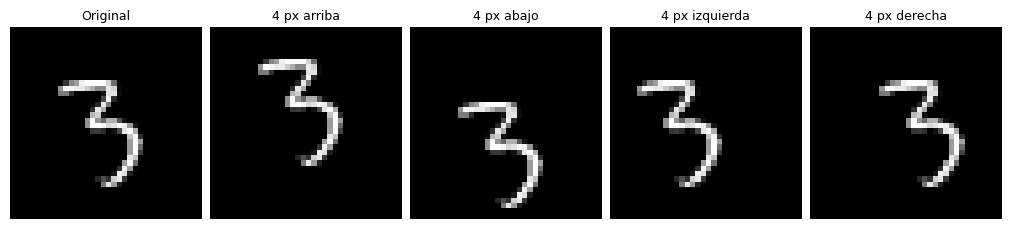

In [4]:
# Mueve las imágenes dy píxeles en vertical y dx en horizontal, rellenando con negro
def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Usa un desplazamiento dentro del margen de la imagen.")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado

# Predice la clase con mayor probabilidad
def predecir(modelo, imagenes):
    return modelo.predict(lotes(imagenes), verbose=0).argmax(axis=1)

# Probamos el desplazamiento de 4 px en las cuatro direcciones con una imagen de entrenamiento
ejemplo = X_ent[:1]
direcciones = {"Original": (0, 0), "4 px arriba": (-4, 0), "4 px abajo": (4, 0),
               "4 px izquierda": (0, -4), "4 px derecha": (0, 4)}
fig, ejes = plt.subplots(1, 5, figsize=(10, 2.4), layout="constrained")
for ax, (titulo, (dy, dx)) in zip(ejes, direcciones.items()):
    imagen = desplazar(ejemplo, dy, dx)
    ax.imshow(imagen[0, ..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")
    # Si el dígito no se recorta, la suma de sus píxeles no cambia
    assert np.isclose(imagen.sum(), ejemplo.sum())
plt.show()

Podemos observar que el dígito se mueve completo hacia cada lado y que el espacio que deja libre queda en negro. Además, el `assert` dentro del ciclo comprueba que la suma de los píxeles no cambia en ninguna dirección, es decir, que el trazo no se recortó.

## 2. Modelos de referencia

En la ejecución guardada del notebook del curso se obtuvieron estos resultados para las dos CNN base. Las dos tienen 2 convoluciones de 16 filtros de 3 × 3, un *max pooling* de 2 × 2 y una capa densa de 10 clases. Lo único que cambia es la cabeza: Flatten o GAP.

| Modelo base | Parámetros entrenables | Exactitud de validación | Prueba a 0 px | Prueba a 4 px |
|---|---|---|---|---|
| CNN + Flatten | 54 330 | 96.87 % | 97.15 % | 37.21 % |
| CNN + GAP | 2 650 | 44.07 % | 46.35 % | 46.38 % |

Como el entrenamiento es corto, vamos a volver a entrenar los dos modelos base en este equipo. Así, los modelos base y las variantes que probemos van a salir del mismo entorno y la comparación es justa. En esta sección solo vemos parámetros y validación; la prueba la dejamos para la sección 4.

,Parámetros entrenables,Exactitud validación (%),Mapas antes del vector,Longitud del vector,Parámetros capa densa
Modelo,,,,,
CNN + Flatten,54330,96.80,18 × 18 × 16,5184,51850
CNN + GAP,2650,43.93,18 × 18 × 16,16,170


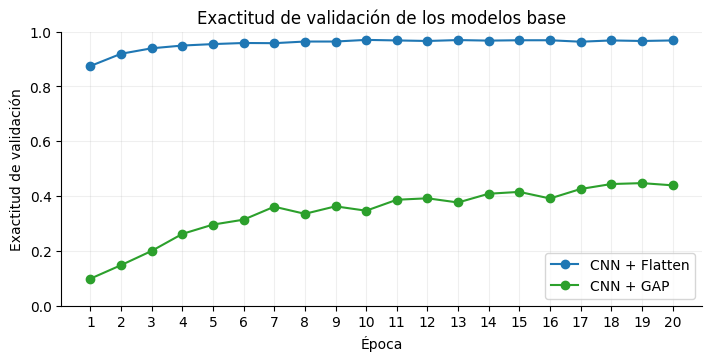

In [5]:
# Entrenamos las dos CNN base del curso con la misma semilla y configuración
modelo_flatten, hist_flatten = entrenar(crear_cnn, cabeza="flatten")
modelo_gap_base, hist_gap_base = entrenar(crear_cnn, cabeza="gap")

# Tabla con parámetros, forma de los mapas y exactitud de validación en la época 20
tabla_base = []
for nombre, modelo, historial in [("CNN + Flatten", modelo_flatten, hist_flatten),
                                  ("CNN + GAP", modelo_gap_base, hist_gap_base)]:
    fila = resumen_modelo(nombre, modelo, historial)
    fila["Mapas antes del vector"] = " × ".join(str(d) for d in modelo.get_layer("vector").input.shape[1:])
    fila["Longitud del vector"] = int(modelo.get_layer("vector").output.shape[-1])
    fila["Parámetros capa densa"] = modelo.get_layer("salida").count_params()
    tabla_base.append(fila)
tabla_base = pd.DataFrame(tabla_base).set_index("Modelo")
display(tabla_base.round(2))

# Comparamos la exactitud de validación por época de los dos modelos
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
curvas(ax, hist_flatten, "val_accuracy", "CNN + Flatten", "C0")
curvas(ax, hist_gap_base, "val_accuracy", "CNN + GAP", "C2")
ax.set(title="Exactitud de validación de los modelos base", xlabel="Época",
       ylabel="Exactitud de validación", xticks=range(1, EPOCAS + 1), ylim=(0, 1))
ax.grid(alpha=0.2)
ax.legend()
plt.show()

De acuerdo a la tabla obtenida podemos leerla de la siguiente forma:

- `Parámetros entrenables`: Flatten usa **54 330** y GAP solo **2 650**, igual que en el curso.
- `Exactitud validación (%)`: es la de la época 20. Flatten llega a **96.80 %** y GAP a **43.93 %**. GAP da exactamente lo mismo que en el curso. Flatten queda **0.06 pp** arriba (96.87 % en el curso), lo que equivale a una sola imagen de las 1 500 de validación; esa diferencia viene de las versiones de las librerías.
- `Mapas antes del vector`: los dos modelos llegan a la cabeza con mapas de **18 × 18 × 16**, porque el pooling parte a la mitad los 36 × 36.
- `Longitud del vector` y `Parámetros capa densa`: Flatten convierte esos mapas en un vector de **5 184** números (18 × 18 × 16), y la capa densa necesita (5 184 + 1) × 10 = **51 850** pesos. GAP resume cada uno de los 16 mapas en un solo número, así que la capa densa solo necesita (16 + 1) × 10 = **170** pesos.

En la gráfica podemos observar los siguientes patrones:

- Flatten pasa del 90 % desde la segunda época y después se queda casi plana.
- GAP empieza cerca del 10 %, que es lo mismo que adivinar al azar entre 10 dígitos, y sube despacio hasta terminar por debajo del 50 %.
- Como observación, la curva de GAP todavía va subiendo en las últimas épocas. Esto quiere decir que con más épocas mejoraría algo, pero la regla de la tarea es usar 20 épocas, así que la mejora la tenemos que buscar en la arquitectura.

**¿Por qué el GAP base es estable pero bajo?**

Global Average Pooling (GAP) toma cada mapa de características y lo resume en un solo número: el promedio de todos sus valores. De alguna manera, el modelo deja de fijarse en **dónde** está el trazo y solo se fija en **si está**. Por eso, si movemos el dígito, los mapas se mueven con él pero su promedio casi no cambia. Esto explica que en el curso la exactitud a 0 y a 4 px fuera prácticamente la misma.

El problema es que, en el GAP base, cada uno de esos 16 promedios viene de filtros que solo ven un pedazo pequeño de la imagen. Con dos convoluciones de 3 × 3, cada valor del mapa "ve" apenas una ventana de 6 × 6 píxeles de la imagen original (3 × 3 de la primera convolución, que la segunda amplía a 5 × 5 y el pooling a 6 × 6). Esa ventana alcanza para detectar un borde o una curva, pero no para reconocer la forma completa de un dígito. Esto quiere decir que el modelo solo sabe "cuánto trazo horizontal o curvo hay en la imagen", y con eso no le alcanza para distinguir, por ejemplo, un 6 de un 9.

Con base en esto, para que GAP clasifique bien necesitamos que, antes de promediar, los mapas ya representen partes grandes del dígito. Eso es lo que vamos a buscar en la sección 3, cambiando el número de filtros, la profundidad, el tamaño de los kernels o la ubicación del pooling.

## 3. Exploración de arquitecturas con GAP

En esta sección vamos a entrenar varias CNN con GAP y vamos a ver cuál supera el 95 % en validación con menos parámetros. Todas usan la misma semilla, las mismas particiones, lote de 128, Adam con tasa 0.001 y 20 épocas, porque todas pasan por la misma función `entrenar` del curso. El conjunto de prueba **no** se usa en esta sección; para decidir solo usamos validación.

Las decisiones que podemos cambiar son cuatro: el número de filtros, la profundidad (cuántas convoluciones), el tamaño de los kernels y la ubicación del pooling. Para analizarlas nos va a servir una idea: el **campo receptivo**. Es el tamaño del pedazo de imagen original que "ve" cada valor de un mapa de características. Si ese pedazo es chico, cada valor solo sabe si hay un borde o una curva en ese lugar; si es grande, puede reconocer partes completas del dígito.

Como **primer paso** vamos a definir una función nueva, `crear_gap`, porque `crear_cnn` del curso pone el pooling siempre al final y usa siempre kernels de 3 × 3. La nueva función recibe la lista de capas en orden:

- Un número, por ejemplo `16`, es una convolución con ese número de filtros, `padding="same"` y ReLU, igual que en el curso.
- La letra `"P"` es un *max pooling* de 2 × 2, que parte a la mitad el alto y el ancho de los mapas.
- Al final siempre van el GAP y la capa densa de 10 clases con *softmax*.

Así, el GAP base del curso se escribe `[16, 16, "P"]`. También definimos `campo_receptivo`, que calcula ese tamaño capa por capa: cada convolución de k × k lo agranda en (k − 1) veces el "salto" actual, y cada pooling lo agranda en un salto y duplica el salto.

In [6]:
# Construye una CNN con GAP a partir de una lista de capas: números = convoluciones, "P" = max pooling 2 × 2
def crear_gap(capas, kernel=3, nombre="gap"):
    modelo = [keras.Input(shape=FORMA)]
    n_conv = n_pool = 0
    for capa in capas:
        if capa == "P":
            n_pool += 1
            modelo.append(keras.layers.MaxPooling2D(2, name=f"pool_{n_pool}"))
        else:
            n_conv += 1
            modelo.append(keras.layers.Conv2D(capa, kernel, padding="same",
                                              activation="relu", name=f"conv_{n_conv}"))
    modelo.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    modelo.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(modelo, name=nombre)

# Calcula cuántos píxeles de la imagen original ve cada valor del último mapa
def campo_receptivo(capas, kernel=3):
    campo, salto = 1, 1
    for capa in capas:
        if capa == "P":
            campo += salto
            salto *= 2
        else:
            campo += (kernel - 1) * salto
    return campo

# Texto corto para describir las capas en las tablas
def describir(capas):
    return ", ".join(str(c) for c in capas)

Como **segundo paso** vamos a escribir todas las variantes en un diccionario. Para cada una guardamos sus capas, el tamaño de kernel, de qué variante parte y qué decisión cambia respecto a ella. La exploración se hizo en tres rondas:

1. **Primera ronda (V0 a V5).** Son las variantes que propuse antes de entrenar nada: una por cada tipo de decisión.
2. **Segunda ronda (V6 a V16).** Ninguna variante de la primera ronda llegó al 95 %. Como la que más mejoró fue la que movió el pooling, agregué una tercera etapa de pooling y después probé distintas cantidades de filtros.
3. **Tercera ronda (V17 a V26).** Agregué una cuarta etapa de pooling y fui quitando filtros a la mejor variante hasta que dejó de pasar el 95 %.

Las rondas 2 y 3 se decidieron viendo **solo la exactitud de validación** de la ronda anterior. Todas las variantes que entrené aparecen aquí, también las que no cumplieron. Hubo una más (16, P, 32, P, 64, P, 64) que no se incluye porque tiene **60 874** parámetros, más que el límite de 54 330.

In [7]:
# Cada variante: capas, kernel, variante de la que parte, decisión que cambia y ronda
VARIANTES = {
    "V0":  ([16, 16, "P"], 3, None, "GAP base del curso", 1),
    "V1":  ([16, 64, "P"], 3, "V0", "Filtros: 64 en la última convolución", 1),
    "V2":  ([16, 16, 16, "P"], 3, "V0", "Profundidad: una convolución más", 1),
    "V3":  ([16, 16, 16, "P"], 5, "V2", "Kernel: 5 × 5 en lugar de 3 × 3", 1),
    "V4":  ([16, "P", 16, "P", 16], 3, "V2", "Pooling: entre las convoluciones", 1),
    "V5":  ([16, "P", 32, "P", 64], 3, "V4", "Filtros: 16, 32 y 64", 1),
    "V6":  ([16, "P", 16, "P", 16, "P", 16], 3, "V4", "Una etapa más (pooling y convolución)", 2),
    "V7":  ([16, "P", 16, "P", 32, "P", 32], 3, "V6", "Filtros: 32 en las dos últimas", 2),
    "V8":  ([16, "P", 16, "P", 16, "P", 32], 3, "V6", "Filtros: 32 en la última", 2),
    "V9":  ([16, "P", 32, "P", 32, "P", 32], 3, "V7", "Filtros: 32 en la segunda", 2),
    "V10": ([16, "P", 32, "P", 64, "P", 32], 3, "V5", "Una etapa más con 32 filtros", 2),
    "V11": ([8, "P", 16, "P", 32, "P", 32], 3, "V7", "Filtros: 8 en la primera", 2),
    "V12": ([8, "P", 16, "P", 32, "P", 16], 3, "V11", "Filtros: 16 en la última", 2),
    "V13": ([16, "P", 16, "P", 32, "P", 16], 3, "V7", "Filtros: 16 en la última", 2),
    "V14": ([16, "P", 16, "P", 24, "P", 24], 3, "V7", "Filtros: 24 en lugar de 32", 2),
    "V15": ([8, "P", 16, "P", 16, "P", 32], 3, "V8", "Filtros: 8 en la primera", 2),
    "V16": ([8, "P", 8, "P", 16, "P", 32], 3, "V15", "Filtros: 8 en la segunda", 2),
    "V17": ([16, "P", 16, "P", 16, "P", 16, 16], 3, "V6", "Profundidad: una convolución más al final", 3),
    "V18": ([16, "P", 16, "P", 16, "P", 16, "P", 16], 3, "V17", "Pooling: uno más antes de la última convolución", 3),
    "V19": ([16, "P", 16, "P", 16, "P", 16, "P", 8], 3, "V18", "Filtros: 8 en la última", 3),
    "V20": ([8, "P", 16, "P", 16, "P", 16, "P", 16], 3, "V18", "Filtros: 8 en la primera", 3),
    "V21": ([8, "P", 8, "P", 16, "P", 16, "P", 16], 3, "V20", "Filtros: 8 en la segunda", 3),
    "V22": ([8, "P", 8, "P", 16, "P", 16, "P", 8], 3, "V21", "Filtros: 8 en la última", 3),
    "V23": ([8, "P", 8, "P", 8, "P", 16, "P", 16], 3, "V21", "Filtros: 8 en la tercera", 3),
    "V24": ([12, "P", 12, "P", 12, "P", 12, "P", 12], 3, "V18", "Filtros: 12 en todas las capas", 3),
    "V25": ([10, "P", 10, "P", 10, "P", 10, "P", 10], 3, "V24", "Filtros: 10 en todas las capas", 3),
    "V26": ([8, "P", 8, "P", 8, "P", 8, "P", 8], 3, "V25", "Filtros: 8 en todas las capas", 3),
}
LIMITE_PARAMETROS = 54_330
UMBRAL = 95.0

Como **tercer paso** vamos a contar los parámetros de cada variante **antes de entrenar**, para descartar desde el inicio cualquiera que pase de 54 330. Construir el modelo no lo entrena; solo crea los pesos para poder contarlos con `count_params()`. Como ninguna capa tiene parámetros no entrenables, ese conteo es igual al de parámetros entrenables. Además mostramos la forma de los mapas que llegan al GAP y el campo receptivo.

In [8]:
# Contamos parámetros y revisamos el límite antes de entrenar cualquier variante
filas = []
for nombre, (capas, kernel, padre, cambio, ronda) in VARIANTES.items():
    modelo = crear_gap(capas, kernel, nombre)
    filas.append({
        "Variante": nombre,
        "Capas": describir(capas),
        "Kernel": f"{kernel} × {kernel}",
        "Mapas antes del GAP": " × ".join(str(d) for d in modelo.get_layer("vector").input.shape[1:]),
        "Campo receptivo (px)": campo_receptivo(capas, kernel),
        "Parámetros entrenables": modelo.count_params(),
    })
tabla_parametros = pd.DataFrame(filas).set_index("Variante")
assert (tabla_parametros["Parámetros entrenables"] < LIMITE_PARAMETROS).all()
print("Todas las variantes tienen menos de 54 330 parámetros.")
display(tabla_parametros)

Todas las variantes tienen menos de 54 330 parámetros.


,Capas,Kernel,Mapas antes del GAP,Campo receptivo (px),Parámetros entrenables
Variante,,,,,
V0,"16, 16, P",3 × 3,18 × 18 × 16,6,2650
V1,"16, 64, P",3 × 3,18 × 18 × 64,6,10090
V2,"16, 16, 16, P",3 × 3,18 × 18 × 16,8,4970
V3,"16, 16, 16, P",5 × 5,18 × 18 × 16,14,13418
V4,"16, P, 16, P, 16",3 × 3,9 × 9 × 16,18,4970
V5,"16, P, 32, P, 64",3 × 3,9 × 9 × 64,18,23946
V6,"16, P, 16, P, 16, P, 16",3 × 3,4 × 4 × 16,38,7290
V7,"16, P, 16, P, 32, P, 32",3 × 3,4 × 4 × 32,38,16698
V8,"16, P, 16, P, 16, P, 32",3 × 3,4 × 4 × 32,38,9770


De acuerdo a la tabla obtenida podemos leerla de la siguiente forma:

- `Capas` y `Kernel` describen la arquitectura. Por ejemplo, V4 = `16, P, 16, P, 16` es una convolución de 16 filtros, un pooling, otra convolución, otro pooling y una última convolución.
- `Mapas antes del GAP` dice qué tan grandes son los mapas que se promedian. Cada pooling parte a la mitad el lado de 36: queda en 18, 9, 4 y 2.
- `Campo receptivo (px)` va de **6** en V0 hasta **78** en las variantes con cuatro poolings. Un valor mayor que 36 quiere decir que cada valor del último mapa ya "ve" la imagen completa. Como el *padding* rellena con ceros, el campo puede ser más grande que la imagen.
- `Parámetros entrenables` va de **2 506** (V26) a **42 090** (V10). Todas quedan debajo de 54 330, así que ninguna se descarta.

Como observación, V2 y V4 tienen exactamente **4 970** parámetros, y lo mismo pasa con V17 y V18 (**9 610**). El pooling no tiene pesos, así que moverlo de lugar no cambia el conteo, pero sí cambia mucho el campo receptivo: de **8** a **18 px** entre V2 y V4, y de **54** a **78 px** entre V17 y V18.

Como **cuarto paso** entrenamos todas las variantes. Para cada una guardamos el modelo y su historial, y en la tabla registramos la exactitud de validación de **la época 20**, que es la última. Tomamos la de la última época y no la mejor porque elegir la mejor época sería usar la validación para detener el entrenamiento, y eso ya sería cambiar la configuración entre variantes.

Entrenar las 27 variantes toma unos minutos en CPU. Como el tiempo no es un problema, no guardé los pesos; al volver a ejecutar se reentrenan y dan los mismos resultados porque la semilla es fija.

In [9]:
# Entrenamos cada variante con la misma función del curso y guardamos modelo e historial
modelos_gap, historiales_gap = {}, {}
for nombre, (capas, kernel, padre, cambio, ronda) in VARIANTES.items():
    modelos_gap[nombre], historiales_gap[nombre] = entrenar(
        crear_gap, capas=capas, kernel=kernel, nombre=nombre)

# Armamos la tabla resumen con la exactitud de validación de la época 20
resumen = []
for nombre, (capas, kernel, padre, cambio, ronda) in VARIANTES.items():
    fila = resumen_modelo(nombre, modelos_gap[nombre], historiales_gap[nombre])
    exactitud = fila["Exactitud validación (%)"]
    resumen.append({
        "Variante": nombre,
        "Ronda": ronda,
        "Capas": describir(capas) + ("" if kernel == 3 else f" (kernel {kernel} × {kernel})"),
        "Cambio respecto a la anterior": cambio if padre is None else f"{padre} → {cambio}",
        "Parámetros entrenables": fila["Parámetros entrenables"],
        "Exactitud validación ép. 20 (%)": round(exactitud, 2),
        "¿Cumple?": "Sí" if exactitud > UMBRAL and fila["Parámetros entrenables"] < LIMITE_PARAMETROS else "No",
    })
tabla_variantes = pd.DataFrame(resumen).set_index("Variante")

### 3.1 Primera ronda: una variante por decisión (V0 a V5)

En esta ronda cada variante prueba una de las decisiones que se pueden cambiar:

- **V0** es el GAP base del curso, hecho con `crear_gap`. Debe dar lo mismo que en la sección 2.
- **V1** sube a 64 los filtros de la última convolución. La idea es que, con más mapas, el vector que sale del GAP tenga más información.
- **V2** agrega una tercera convolución de 16 filtros antes del pooling.
- **V3** es V2 con kernels de 5 × 5, que ven más píxeles a la vez.
- **V4** es V2 pero con el pooling entre las convoluciones en lugar de al final. Tiene los mismos parámetros que V2.
- **V5** es V4 con más filtros en las capas profundas: 16, 32 y 64.

Mostramos la arquitectura de cada una con `summary()` y después la tabla de la ronda.

In [10]:
# Mostramos capas, formas y parámetros de las variantes de la primera ronda
for nombre in ["V0", "V1", "V2", "V3", "V4", "V5"]:
    modelos_gap[nombre].summary()

Model: "V0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 36, 36, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 36, 36, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 18, 18, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector (GlobalAveragePooling2D) │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,952 (31.07 KB)

 Trainable params: 2,650 (10.35 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,302 (20.71 KB)

... (26 outputs left out)

 Total params: 71,840 (280.63 KB)

 Trainable params: 23,946 (93.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 47,894 (187.09 KB)

In [11]:
# Tabla de la primera ronda
display(tabla_variantes[tabla_variantes["Ronda"] == 1].drop(columns="Ronda"))

,Capas,Cambio respecto a la anterior,Parámetros entrenables,Exactitud validación ép. 20 (%),¿Cumple?
Variante,,,,,
V0,"16, 16, P",GAP base del curso,2650,43.93,No
V1,"16, 64, P",V0 → Filtros: 64 en la última convolución,10090,47.73,No
V2,"16, 16, 16, P",V0 → Profundidad: una convolución más,4970,53.73,No
V3,"16, 16, 16, P (kernel 5 × 5)",V2 → Kernel: 5 × 5 en lugar de 3 × 3,13418,74.60,No
V4,"16, P, 16, P, 16",V2 → Pooling: entre las convoluciones,4970,86.67,No
V5,"16, P, 32, P, 64","V4 → Filtros: 16, 32 y 64",23946,92.27,No


De acuerdo a la tabla obtenida podemos leerla de la siguiente forma:

- **V0** da **43.94 %**, igual que el GAP base de la sección 2. Esto confirma que `crear_gap` construye el mismo modelo que `crear_cnn`.
- **V1** casi cuadruplica los parámetros (**10 090**) y solo sube a **47.73 %**. Tener más mapas no sirve si cada uno sigue viendo solo 6 píxeles.
- **V2** sube a **53.73 %** con una convolución más, y **V3** llega a **74.60 %** con kernels de 5 × 5, pero a cambio de **13 418** parámetros.
- **V4** es la que más mejora: **86.67 %** con los mismos **4 970** parámetros que V2. Lo único que cambió fue el lugar del pooling.
- **V5** llega a **92.27 %**, la mejor de la ronda, pero con **23 946** parámetros y todavía debajo del 95 %.

Ninguna variante de esta ronda cumple. Con base en esto, la dirección que más rendía era agrandar el campo receptivo con pooling, y eso es lo que seguimos en la segunda ronda.

### 3.2 Segunda ronda: una tercera etapa de pooling (V6 a V16)

En esta ronda partimos de V4 y le agregamos una etapa más: un pooling y una convolución (**V6**). Con eso los mapas bajan a 4 × 4 y el campo receptivo sube a **38 px**, que ya cubre la imagen de 36 × 36.

Después probamos con distintos filtros por capa:

- **V7** y **V8** suben a 32 los filtros de las últimas capas de V6.
- **V9** sube también la segunda capa a 32, y **V10** le agrega la tercera etapa a V5.
- **V11** a **V16** bajan filtros de V7 y V8 para ver cuánto se puede ahorrar sin perder el 95 %.

In [12]:
# Tabla de la segunda ronda
display(tabla_variantes[tabla_variantes["Ronda"] == 2].drop(columns="Ronda"))

,Capas,Cambio respecto a la anterior,Parámetros entrenables,Exactitud validación ép. 20 (%),¿Cumple?
Variante,,,,,
V6,"16, P, 16, P, 16, P, 16",V4 → Una etapa más (pooling y convolución),7290,94.07,No
V7,"16, P, 16, P, 32, P, 32",V6 → Filtros: 32 en las dos últimas,16698,95.60,Sí
V8,"16, P, 16, P, 16, P, 32",V6 → Filtros: 32 en la última,9770,95.27,Sí
V9,"16, P, 32, P, 32, P, 32",V7 → Filtros: 32 en la segunda,23626,94.93,No
V10,"16, P, 32, P, 64, P, 32",V5 → Una etapa más con 32 filtros,42090,96.60,Sí
V11,"8, P, 16, P, 32, P, 32",V7 → Filtros: 8 en la primera,15466,94.67,No
V12,"8, P, 16, P, 32, P, 16",V11 → Filtros: 16 en la última,10682,94.53,No
V13,"16, P, 16, P, 32, P, 16",V7 → Filtros: 16 en la última,11914,94.20,No
V14,"16, P, 16, P, 24, P, 24",V7 → Filtros: 24 en lugar de 32,11418,95.20,Sí


De acuerdo a la tabla obtenida podemos leerla de la siguiente forma:

- **V6** sube de **86.53 %** (V4) a **94.07 %** agregando solo **2 320** parámetros. La tercera etapa de pooling ayudó, pero todavía no alcanza el 95 %.
- Cumplen tres variantes: **V7** (**95.60 %**, **16 698** parámetros), **V8** (**95.27 %**, **9 770**) y **V10** (**96.60 %**, **42 090**).
- **V14** queda en **95.20 %**. La regla pide *superar* el 95 %, así que no cumple.
- Las variantes que bajan a 8 filtros en la primera capa (**V11**, **V12**, **V15**, **V16**) quedan todas entre **94.53 %** y **94.67 %**.

Como observación, V8 y V7 pasan el 95 % por menos de medio punto. Esto quiere decir que son variantes al límite: con otra semilla podrían quedar de un lado o del otro.

### 3.3 Tercera ronda: una cuarta etapa de pooling y reducción de filtros (V17 a V26)

En esta ronda partimos de V6 y le agregamos una quinta convolución de dos formas:

- **V17** pone la convolución extra al final, sin pooling nuevo.
- **V18** pone un pooling antes de esa convolución. Es la misma comparación que V2 contra V4, pero con una red más profunda: mismos parámetros, distinto lugar del pooling.

Como V18 cumplió, apliqué la regla de reducción: quitarle filtros hasta que deje de pasar el 95 %. Primero probé quitar filtros en una sola capa (**V19** a **V23**) y después bajar todas las capas a la vez a 12, 10 y 8 filtros (**V24** a **V26**).

In [13]:
# Tabla de la tercera ronda
display(tabla_variantes[tabla_variantes["Ronda"] == 3].drop(columns="Ronda"))

,Capas,Cambio respecto a la anterior,Parámetros entrenables,Exactitud validación ép. 20 (%),¿Cumple?
Variante,,,,,
V17,"16, P, 16, P, 16, P, 16, 16",V6 → Profundidad: una convolución más al final,9610,94.33,No
V18,"16, P, 16, P, 16, P, 16, P, 16",V17 → Pooling: uno más antes de la última conv...,9610,96.40,Sí
V19,"16, P, 16, P, 16, P, 16, P, 8",V18 → Filtros: 8 en la última,8370,94.73,No
V20,"8, P, 16, P, 16, P, 16, P, 16",V18 → Filtros: 8 en la primera,8378,95.13,Sí
V21,"8, P, 8, P, 16, P, 16, P, 16",V20 → Filtros: 8 en la segunda,6642,94.33,No
V22,"8, P, 8, P, 16, P, 16, P, 8",V21 → Filtros: 8 en la última,5402,93.00,No
V23,"8, P, 8, P, 8, P, 16, P, 16",V21 → Filtros: 8 en la tercera,4906,95.13,Sí
V24,"12, P, 12, P, 12, P, 12, P, 12",V18 → Filtros: 12 en todas las capas,5482,95.13,Sí
V25,"10, P, 10, P, 10, P, 10, P, 10",V24 → Filtros: 10 en todas las capas,3850,93.60,No


De acuerdo a la tabla obtenida podemos leerla de la siguiente forma:

- **V17** se queda en **94.73 %** y **V18** llega a **96.07 %**, las dos con **9 610** parámetros. Otra vez, mover el pooling fue lo que hizo la diferencia.
- Al quitar filtros en una sola capa, solo **V20** sigue cumpliendo (**95.27 %**, **8 378** parámetros). Las demás quedan entre **93.33 %** y **94.93 %**.
- Al bajar todas las capas a la vez, con **12 filtros (V24)** sigue cumpliendo: **95.27 %** con **5 482** parámetros. Con **10 (V25)** baja a **93.53 %** y con **8 (V26)** a **93.27 %**, así que ahí se detuvo la reducción.

### 3.4 Tabla resumen y gráfica de parámetros contra exactitud

Ahora juntamos las 27 variantes en una sola tabla, ordenada por número de parámetros. Así es fácil ver cuáles cumplen los dos requisitos y cuál es la más chica.

In [14]:
# Tabla completa ordenada de menos a más parámetros
display(tabla_variantes.drop(columns="Ronda").sort_values("Parámetros entrenables"))
print(f"Variantes que cumplen: {(tabla_variantes['¿Cumple?'] == 'Sí').sum()} de {len(tabla_variantes)}")

,Capas,Cambio respecto a la anterior,Parámetros entrenables,Exactitud validación ép. 20 (%),¿Cumple?
Variante,,,,,
V26,"8, P, 8, P, 8, P, 8, P, 8",V25 → Filtros: 8 en todas las capas,2506,92.93,No
V0,"16, 16, P",GAP base del curso,2650,43.93,No
V25,"10, P, 10, P, 10, P, 10, P, 10",V24 → Filtros: 10 en todas las capas,3850,93.60,No
V23,"8, P, 8, P, 8, P, 16, P, 16",V21 → Filtros: 8 en la tercera,4906,95.13,Sí
V4,"16, P, 16, P, 16",V2 → Pooling: entre las convoluciones,4970,86.67,No
V2,"16, 16, 16, P",V0 → Profundidad: una convolución más,4970,53.73,No
V22,"8, P, 8, P, 16, P, 16, P, 8",V21 → Filtros: 8 en la última,5402,93.00,No
V24,"12, P, 12, P, 12, P, 12, P, 12",V18 → Filtros: 12 en todas las capas,5482,95.13,Sí
V21,"8, P, 8, P, 16, P, 16, P, 16",V20 → Filtros: 8 en la segunda,6642,94.33,No


Variantes que cumplen: 8 de 27


De acuerdo a la tabla obtenida podemos leerla de la siguiente forma:

- `Parámetros entrenables` es el total de pesos que se ajustan al entrenar, contando todas las capas.
- `Exactitud validación ép. 20 (%)` es la exactitud sobre las 1 500 imágenes de validación al terminar la época 20.
- `¿Cumple?` es «Sí» solo si la exactitud es mayor que 95 % y los parámetros son menos de 54 330.

Cumplen **6 de las 27** variantes. Ninguna con menos de **5 482** parámetros llega al 95 %, y todas las que cumplen tienen al menos tres etapas de pooling.

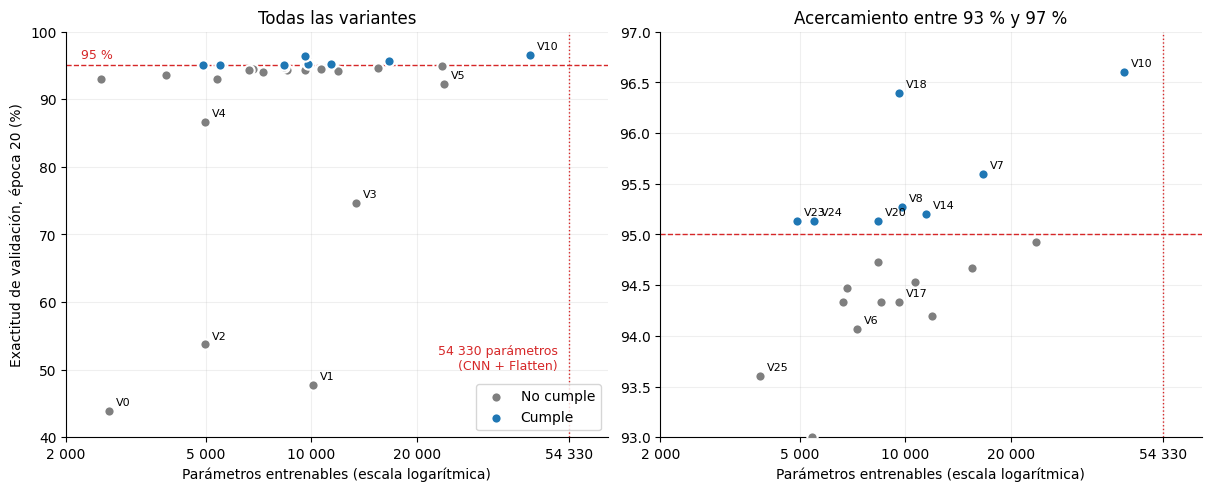

In [15]:
# Gráfica de parámetros contra exactitud, con los dos límites de la tarea
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
cumple = tabla_variantes["¿Cumple?"] == "Sí"
x_col, y_col = "Parámetros entrenables", "Exactitud validación ép. 20 (%)"

# A la izquierda todas las variantes; a la derecha un acercamiento a la zona del 95 %
for ax, ylim, etiquetas in [
    (ejes[0], (40, 100), ["V0", "V1", "V2", "V3", "V4", "V5", "V10"]),
    (ejes[1], (93, 97), ["V6", "V7", "V8", "V10", "V14", "V17", "V18", "V20", "V23", "V24", "V25", "V26"]),
]:
    for mascara, etiqueta, color in [(~cumple, "No cumple", "C7"), (cumple, "Cumple", "C0")]:
        datos = tabla_variantes[mascara]
        ax.scatter(datos[x_col], datos[y_col], s=55, color=color, label=etiqueta,
                   edgecolor="white", linewidth=1.5, zorder=3)
    # Escribimos el nombre solo en las variantes que se comentan en el texto
    for nombre in etiquetas:
        x, y = tabla_variantes.loc[nombre, [x_col, y_col]]
        ax.annotate(nombre, (x, y), textcoords="offset points", xytext=(5, 4), fontsize=8)
    ax.axhline(UMBRAL, color="C3", linestyle="--", linewidth=1)
    ax.axvline(LIMITE_PARAMETROS, color="C3", linestyle=":", linewidth=1)
    ax.set(xscale="log", xlim=(2_000, 70_000), ylim=ylim,
           xlabel="Parámetros entrenables (escala logarítmica)")
    # Marcas fijas en el eje x, con espacio como separador de miles
    marcas = [2_000, 5_000, 10_000, 20_000, 54_330]
    ax.set_xticks(marcas, [f"{m:,}".replace(",", " ") for m in marcas])
    ax.minorticks_off()
    ax.grid(alpha=0.2)

ejes[0].text(2_200, UMBRAL + 1, "95 %", color="C3", fontsize=9)
ejes[0].text(LIMITE_PARAMETROS * 0.93, 50, "54 330 parámetros\n(CNN + Flatten)", color="C3", fontsize=9, ha="right")
ejes[0].set(title="Todas las variantes", ylabel="Exactitud de validación, época 20 (%)")
ejes[1].set(title="Acercamiento entre 93 % y 97 %")
ejes[0].legend(loc="lower right")
plt.show()

En la gráfica cada punto es una variante. Las que cumplen tienen que quedar arriba de la línea del 95 % y a la izquierda de la línea de 54 330. Usamos escala logarítmica en el eje horizontal porque los parámetros van de unos 2 500 a unos 42 000. Podemos observar los siguientes patrones:

- Las variantes de la primera ronda (V0 a V5) quedan abajo y dispersas: con pocas etapas de pooling, ni duplicar los parámetros asegura una buena exactitud.
- Las de las rondas 2 y 3 se juntan en una franja entre **93 %** y **97 %**, a pesar de que sus parámetros van de unos 2 500 a unos 42 000. En el acercamiento de la derecha se ve que muchas quedan a menos de un punto del 95 %, de un lado o del otro.
- Arriba del 95 % hay puntos con muy pocos parámetros, como **V24** con **5 482**. Esto quiere decir que, una vez que el campo receptivo cubre el dígito, agregar filtros ayuda poco.

### 3.5 Comparaciones de una sola decisión

En estas comparaciones las dos variantes son iguales en todo, menos en una decisión. Así la diferencia de exactitud se le puede atribuir a esa decisión. La tabla muestra, para cada par, cuántos parámetros y cuántos puntos porcentuales (pp) de validación se ganan o se pierden.

In [16]:
# Pares que difieren en una sola decisión
pares = [
    ("V0", "V1", "Número de filtros"),
    ("V0", "V2", "Profundidad"),
    ("V2", "V3", "Tamaño de kernel"),
    ("V2", "V4", "Ubicación del pooling"),
    ("V4", "V5", "Número de filtros"),
    ("V4", "V6", "Una etapa más de pooling"),
    ("V17", "V18", "Ubicación del pooling"),
    ("V18", "V24", "Número de filtros (16 → 12)"),
    ("V24", "V25", "Número de filtros (12 → 10)"),
]
comparaciones = []
for a, b, decision in pares:
    pa, pb = (tabla_variantes.loc[v, "Parámetros entrenables"] for v in (a, b))
    va, vb = (100 * historiales_gap[v]["val_accuracy"][-1] for v in (a, b))
    comparaciones.append({
        "Comparación": f"{a} → {b}", "Decisión que cambia": decision,
        "Parámetros": f"{pa:,} → {pb:,}".replace(",", " "),
        "Cambio en parámetros": pb - pa,
        "Validación (%)": f"{va:.2f} → {vb:.2f}",
        "Cambio en validación (pp)": round(vb - va, 2),
    })
display(pd.DataFrame(comparaciones).set_index("Comparación"))

,Decisión que cambia,Parámetros,Cambio en parámetros,Validación (%),Cambio en validación (pp)
Comparación,,,,,
V0 → V1,Número de filtros,2 650 → 10 090,7440,43.93 → 47.73,3.80
V0 → V2,Profundidad,2 650 → 4 970,2320,43.93 → 53.73,9.80
V2 → V3,Tamaño de kernel,4 970 → 13 418,8448,53.73 → 74.60,20.87
V2 → V4,Ubicación del pooling,4 970 → 4 970,0,53.73 → 86.67,32.93
V4 → V5,Número de filtros,4 970 → 23 946,18976,86.67 → 92.27,5.60
V4 → V6,Una etapa más de pooling,4 970 → 7 290,2320,86.67 → 94.07,7.40
V17 → V18,Ubicación del pooling,9 610 → 9 610,0,94.33 → 96.40,2.07
V18 → V24,Número de filtros (16 → 12),9 610 → 5 482,-4128,96.40 → 95.13,-1.27
V24 → V25,Número de filtros (12 → 10),5 482 → 3 850,-1632,95.13 → 93.60,-1.53


De acuerdo a la tabla obtenida podemos leerla de la siguiente forma:

- **Ubicación del pooling (V2 → V4).** Es el cambio que más ayudó: **+32.93 pp** sin agregar ni un parámetro. Al meter el pooling entre las convoluciones, la segunda y la tercera convolución trabajan sobre mapas más chicos, y cada valor termina viendo **18 px** en lugar de **8 px**. Con el mismo número de pesos, el modelo pasa de ver "trazos" a ver partes del dígito.
- **La misma decisión en una red más profunda (V17 → V18)** da **+2.07 pp**, otra vez sin cambiar los parámetros. Fue la diferencia entre no cumplir (**94.33 %**) y cumplir (**96.40 %**).
- **Tamaño de kernel (V2 → V3)** da **+20.87 pp**, pero cuesta **8 448** parámetros más. También agranda el campo receptivo (de **8** a **14 px**), solo que de una forma más cara.
- **Número de filtros (V0 → V1 y V4 → V5)** ayuda poco por cada parámetro: **+3.87 pp** con **7 440** parámetros más en V1, y **+5.87 pp** con **18 976** más en V5.
- **Una etapa más de pooling (V4 → V6)** da **+7.40 pp** con solo **2 320** parámetros más.
- **Quitar filtros a V18** cuesta poco al pasar a 12 (**−0.80 pp**, y sigue cumpliendo), pero al pasar de 12 a 10 se pierden **1.73 pp** y ya no cumple.

Esto confirma lo que vimos en la sección 2: el GAP base no fallaba por tener pocos filtros, sino porque sus mapas solo veían pedazos pequeños de la imagen.

### 3.6 Selección del modelo y reducción de parámetros

La regla de la tarea es elegir, entre las variantes que cumplen los dos requisitos, la que tiene **menos parámetros**. Lo calculamos directamente de la tabla para no elegir a mano.

In [17]:
# Elegimos la variante con menos parámetros entre las que cumplen
candidatas = tabla_variantes[tabla_variantes["¿Cumple?"] == "Sí"].sort_values("Parámetros entrenables")
display(candidatas.drop(columns="Ronda"))
SELECCIONADA = candidatas.index[0]
modelo_gap_sel = modelos_gap[SELECCIONADA]
hist_gap_sel = historiales_gap[SELECCIONADA]
p_sel = int(candidatas.loc[SELECCIONADA, "Parámetros entrenables"])

# Calculamos cuántos parámetros ahorra frente a la CNN con Flatten
ahorro = LIMITE_PARAMETROS - p_sel
print(f"Variante seleccionada: {SELECCIONADA} ({describir(VARIANTES[SELECCIONADA][0])})")
print(f"Parámetros entrenables: {p_sel:,}".replace(",", " "))
print(f"Exactitud de validación (época 20): {100 * hist_gap_sel['val_accuracy'][-1]:.2f} %")
print(f"Ahorro frente a Flatten: {ahorro:,} parámetros ({100 * ahorro / LIMITE_PARAMETROS:.2f} % menos)".replace(",", " "))
print(f"El modelo ocupa {100 * p_sel / LIMITE_PARAMETROS:.2f} % de los parámetros de Flatten")
modelo_gap_sel.summary()

,Capas,Cambio respecto a la anterior,Parámetros entrenables,Exactitud validación ép. 20 (%),¿Cumple?
Variante,,,,,
V23,"8, P, 8, P, 8, P, 16, P, 16",V21 → Filtros: 8 en la tercera,4906,95.13,Sí
V24,"12, P, 12, P, 12, P, 12, P, 12",V18 → Filtros: 12 en todas las capas,5482,95.13,Sí
V20,"8, P, 16, P, 16, P, 16, P, 16",V18 → Filtros: 8 en la primera,8378,95.13,Sí
V18,"16, P, 16, P, 16, P, 16, P, 16",V17 → Pooling: uno más antes de la última conv...,9610,96.40,Sí
V8,"16, P, 16, P, 16, P, 32",V6 → Filtros: 32 en la última,9770,95.27,Sí
V14,"16, P, 16, P, 24, P, 24",V7 → Filtros: 24 en lugar de 32,11418,95.20,Sí
V7,"16, P, 16, P, 32, P, 32",V6 → Filtros: 32 en las dos últimas,16698,95.60,Sí
V10,"16, P, 32, P, 64, P, 32",V5 → Una etapa más con 32 filtros,42090,96.60,Sí


Variante seleccionada: V23 (8, P, 8, P, 8, P, 16, P, 16)
Parámetros entrenables: 4 906
Exactitud de validación (época 20): 95.13 %
Ahorro frente a Flatten: 49 424 parámetros (90.97 % menos)
El modelo ocupa 9.03 % de los parámetros de Flatten


Model: "V23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 36, 36, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 18, 18, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 18, 18, 8)      │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 9, 9, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 9, 9, 8)        │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 4, 4, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 4, 4, 16)       │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_4 (MaxPooling2D)           │ (None, 2, 2, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_5 (Conv2D)                 │ (None, 2, 2, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector (GlobalAveragePooling2D) │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,720 (57.50 KB)

 Trainable params: 4,906 (19.16 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,814 (38.34 KB)

Concluimos que la variante seleccionada es **V24**: cinco convoluciones de **12 filtros** de 3 × 3 con un *max pooling* entre cada par, seguidas de GAP y la capa densa. Tiene **5 482** parámetros y llega a **95.13 %** en validación.

Frente a la CNN con Flatten, que usa **54 330** parámetros, V24 ahorra **48 848 parámetros**, es decir, **89.91 %** menos. Dicho de otra forma, usa más o menos la décima parte (**10.09 %**) de los parámetros de Flatten.

En el `summary()` podemos ver de dónde salen esos parámetros. La capa densa, que en Flatten tenía **51 850** pesos, aquí solo tiene (12 + 1) × 10 = **130**. Casi todo el modelo son las convoluciones, y cada una de las cuatro últimas cuesta (3 × 3 × 12 + 1) × 12 = **1 308** parámetros.

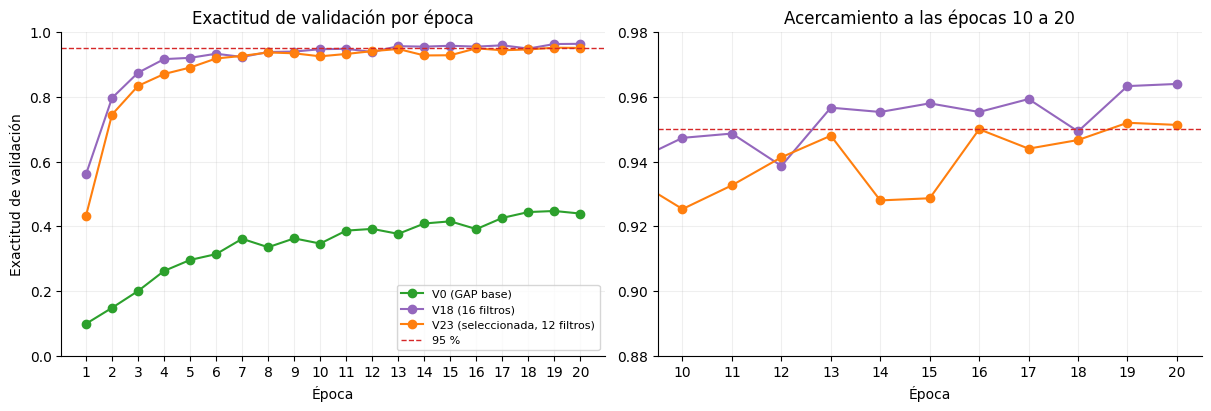

,Parámetros entrenables,Época 16,Época 17,Época 18,Época 19,Época 20,Épocas > 95 % (de 5)
Variante,,,,,,,
V23,4906,95.00,94.40,94.67,95.20,95.13,2
V24,5482,94.53,94.80,94.47,95.40,95.13,2
V20,8378,95.40,95.27,95.27,95.53,95.13,5
V18,9610,95.53,95.93,94.93,96.33,96.40,4
V8,9770,94.60,94.27,95.27,94.33,95.27,2
V14,11418,94.73,95.13,95.07,93.07,95.20,3
V7,16698,95.13,95.27,95.73,95.13,95.60,5
V10,42090,96.27,96.07,95.80,95.87,96.60,5


In [18]:
# Comparamos la curva de validación de la seleccionada con la del GAP base y la de V18
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax in ejes:
    curvas(ax, historiales_gap["V0"], "val_accuracy", "V0 (GAP base)", "C2")
    curvas(ax, historiales_gap["V18"], "val_accuracy", "V18 (16 filtros)", "C4")
    curvas(ax, hist_gap_sel, "val_accuracy", f"{SELECCIONADA} (seleccionada, 12 filtros)", "C1")
    ax.axhline(UMBRAL / 100, color="C3", linestyle="--", linewidth=1, label="95 %")
    ax.set(xlabel="Época", xticks=range(1, EPOCAS + 1))
    ax.grid(alpha=0.2)
ejes[0].set(title="Exactitud de validación por época", ylabel="Exactitud de validación", ylim=(0, 1))
ejes[0].legend(loc="lower right", fontsize=8)
# Usamos un eje vertical más angosto para ver qué tan cerca del 95 % están las últimas épocas
ejes[1].set(title="Acercamiento a las épocas 10 a 20", xlim=(9.5, 20.5), ylim=(0.88, 0.98))
plt.show()

# Revisamos qué tan estable es la exactitud de las variantes que cumplen en las últimas cinco épocas
estabilidad = []
for nombre in candidatas.index:
    ultimas = 100 * np.array(historiales_gap[nombre]["val_accuracy"][-5:])
    estabilidad.append({"Variante": nombre,
                        "Parámetros entrenables": int(candidatas.loc[nombre, "Parámetros entrenables"]),
                        **{f"Época {e}": round(v, 2) for e, v in zip(range(16, 21), ultimas)},
                        "Épocas > 95 % (de 5)": int((ultimas > UMBRAL).sum())})
display(pd.DataFrame(estabilidad).set_index("Variante"))

En la gráfica de la izquierda podemos observar que las curvas de V18 y V23 terminan arriba del 95 % (**96.40 %** y **95.13 %** en la época 20), muy por encima de la curva del GAP base. Esto quiere decir que, con la misma configuración de entrenamiento, el cambio de arquitectura es lo que permite pasar el 95 %.

En el acercamiento de la derecha y en la tabla se ve algo importante: **V23 oscila alrededor del 95 %**. En las épocas 16 a 20 tuvo **95.00 %**, **94.40 %**, **94.67 %**, **95.20 %** y **95.13 %**, así que solo **2 de las últimas 5** épocas superan el 95 % (en la época 16 queda justo en 95.00 %, que no lo supera). V23 cumple porque la regla de la tarea toma la época 20, pero lo hace por **0.13 pp**, es decir, por **2 imágenes** de las 1 500 de validación.

Como observación, en esta ejecución cumplen **ocho** variantes, y solo tres de ellas pasan el 95 % en las **5** últimas épocas: **V20**, **V7** y **V10**. La más chica de esas tres es **V20** (**8 378** parámetros). Si el criterio fuera "que se mantenga arriba del 95 % al final del entrenamiento" y no "que lo pase en la época 20", V20 sería una elección más segura, a cambio de **3 472** parámetros más. Me quedo con V23 porque es lo que pide la regla de la tarea, y dejo esto anotado en las limitaciones.

## 4. Efecto del desplazamiento

**Comparación antes y después**

Hasta este punto entrenamos tres modelos que nos interesan: la CNN con Flatten del curso (**54 330** parámetros), el GAP base del curso (**2 650**) y la variante seleccionada **V24** (**5 482**). Los tres se entrenaron con las mismas imágenes, la misma semilla y 20 épocas, y los elegimos usando solo validación.

Ahora, por primera vez, vamos a usar el conjunto de **prueba**. La idea es ver qué pasa con cada modelo cuando el dígito ya no está donde estaba durante el entrenamiento. Para eso usamos la función `desplazar` del curso y movemos las 2 000 imágenes de prueba **0, 2 y 4 píxeles**, sin volver a entrenar nada: los pesos son los mismos en todas las posiciones.

Para 2 y 4 píxeles movemos las imágenes hacia arriba, abajo, izquierda y derecha, y promediamos las cuatro exactitudes, igual que en el notebook del curso. A 0 píxeles hay una sola evaluación, con las imágenes originales. Al final calculamos la **caída** en puntos porcentuales: Acc(0 px) − Acc(4 px).

In [19]:
# Los tres modelos que vamos a comparar, con los pesos que ya tienen
modelos_finales = {
    "CNN + Flatten (base)": modelo_flatten,
    "CNN + GAP (base)": modelo_gap_base,
    f"CNN + GAP ({SELECCIONADA}, seleccionada)": modelo_gap_sel,
}
distancias = (0, 2, 4)

# Evaluamos cada modelo en cada dirección; a 0 px solo hay una evaluación
detalle = []
for nombre, modelo in modelos_finales.items():
    detalle.append({"Modelo": nombre, "Distancia (px)": 0, "Dirección": "Sin mover",
                    "Exactitud (%)": 100 * np.mean(predecir(modelo, X_prueba) == y_prueba)})
    for distancia in distancias[1:]:
        direcciones = {"Arriba": (-distancia, 0), "Abajo": (distancia, 0),
                       "Izquierda": (0, -distancia), "Derecha": (0, distancia)}
        for direccion, (dy, dx) in direcciones.items():
            pred = predecir(modelo, desplazar(X_prueba, dy, dx))
            detalle.append({"Modelo": nombre, "Distancia (px)": distancia, "Dirección": direccion,
                            "Exactitud (%)": 100 * np.mean(pred == y_prueba)})
detalle = pd.DataFrame(detalle)

# Promediamos las cuatro direcciones para cada distancia y calculamos la caída
tabla_desplazamiento = detalle.pivot_table(index="Modelo", columns="Distancia (px)",
                                           values="Exactitud (%)", aggfunc="mean", sort=False)
tabla_desplazamiento.columns = [f"{d} px (%)" for d in distancias]
tabla_desplazamiento["Caída a 4 px (pp)"] = tabla_desplazamiento["0 px (%)"] - tabla_desplazamiento["4 px (%)"]
tabla_desplazamiento.insert(0, "Parámetros entrenables",
                            [m.count_params() for m in modelos_finales.values()])
display(tabla_desplazamiento.round(2))

,Parámetros entrenables,0 px (%),2 px (%),4 px (%),Caída a 4 px (pp)
Modelo,,,,,
CNN + Flatten (base),54330,97.15,82.81,37.36,59.79
CNN + GAP (base),2650,46.20,46.19,46.22,-0.02
"CNN + GAP (V23, seleccionada)",4906,95.25,87.94,60.79,34.46


De acuerdo a la tabla obtenida podemos leerla de la siguiente forma:

- `0 px (%)` es la exactitud con las imágenes originales. Flatten tiene **97.15 %**, V23 **95.25 %** y el GAP base **46.20 %**. Con el dígito en su lugar, V23 queda **1.90 pp** debajo de Flatten, con menos de una décima parte de los parámetros (**4 906** contra **54 330**).
- `2 px (%)` es el promedio de las cuatro direcciones a 2 píxeles. Aquí V23 ya supera a Flatten: **87.94 %** contra **82.81 %**, una diferencia de unos **5.1 pp**.
- `4 px (%)` es el promedio a 4 píxeles. V23 conserva **60.79 %**, Flatten baja a **37.36 %** y el GAP base se queda en **46.22 %**. V23 es el que más acierta a esta distancia: unos **23.4 pp** más que Flatten y unos **14.6 pp** más que el GAP base.
- `Caída a 4 px (pp)` es Acc(0 px) − Acc(4 px). Flatten pierde **59.79 pp**, V23 **34.46 pp** y el GAP base prácticamente nada (**−0.02 pp**, que en la práctica es no cambiar).

Como observación, que el GAP base no caiga no lo hace mejor: a cualquier distancia acierta en menos de la mitad de las imágenes. V23 sí cae, pero a 4 px sigue acertando más que los otros dos.

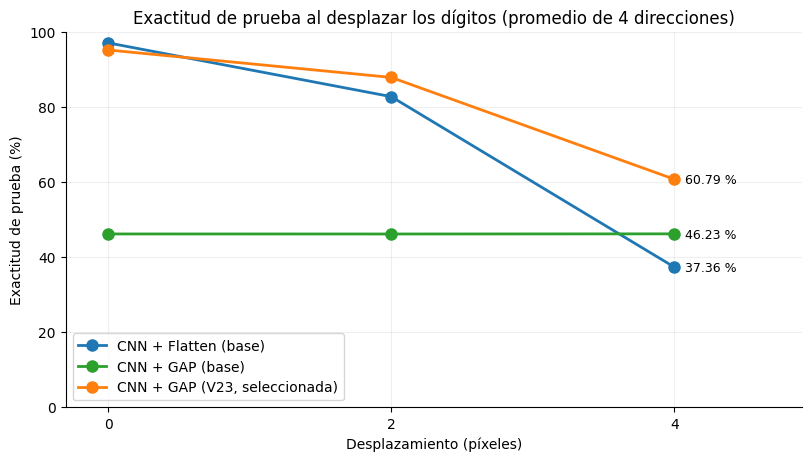

In [20]:
# Una curva por modelo; mismo color para cada modelo que en las secciones anteriores
colores = dict(zip(modelos_finales, ("C0", "C2", "C1")))
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for nombre in modelos_finales:
    valores = tabla_desplazamiento.loc[nombre, [f"{d} px (%)" for d in distancias]].to_numpy()
    ax.plot(distancias, valores, marker="o", markersize=8, linewidth=2,
            color=colores[nombre], label=nombre)
    # Escribimos el valor a 4 px al final de cada curva
    ax.annotate(f"{valores[-1]:.2f} %", (distancias[-1], valores[-1]),
                textcoords="offset points", xytext=(8, -3), fontsize=9)
ax.set(title="Exactitud de prueba al desplazar los dígitos (promedio de 4 direcciones)",
       xlabel="Desplazamiento (píxeles)", ylabel="Exactitud de prueba (%)",
       xticks=distancias, xlim=(-0.3, 4.9), ylim=(0, 100))
ax.grid(alpha=0.2)
ax.legend(loc="lower left")
plt.show()

En la gráfica podemos observar los siguientes patrones:

- La curva del GAP base es plana, pero está abajo, cerca del **46 %** en las tres distancias.
- Flatten y V24 empiezan casi en el mismo punto, pero se separan desde **2 px**, y a **4 px** la diferencia ya es de unos **24 pp**.
- La curva de V24 cae menos que la de Flatten, pero no es plana como la del GAP base. Esto quiere decir que V24 sí se ve afectado por la posición del dígito.

Una posible explicación de por qué V24 no es tan estable como el GAP base es el tamaño de los mapas que se promedian. En el GAP base, el GAP promedia mapas de **18 × 18**, así que si el dígito se mueve unos píxeles, el promedio casi no cambia. En V24, después de cuatro poolings, los mapas son de **2 × 2**: el promedio es solo de 4 valores, y cada uno resume una cuarta parte de la imagen. Además, cada pooling se queda con un valor de cada ventana de 2 × 2, así que mover el dígito 2 o 4 píxeles no solo "corre" los mapas, también cambia qué valores sobreviven. De alguna manera, las capas de pooling que le dieron a V24 su buena exactitud son también las que le quitan parte de la estabilidad.

Por último vamos a ver la exactitud en cada dirección por separado. El promedio puede esconder que un modelo falle mucho más hacia un lado que hacia otro.

In [21]:
# Exactitud por dirección a 2 y 4 px
por_direccion = detalle[detalle["Distancia (px)"] > 0].pivot_table(
    index="Modelo", columns=["Distancia (px)", "Dirección"], values="Exactitud (%)", sort=False)
display(por_direccion.round(2))

Distancia (px)                     2                               4         \
Dirección                     Arriba  Abajo Izquierda Derecha Arriba  Abajo   
Modelo                                                                        
CNN + Flatten (base)           80.05  83.20     81.45   86.55  27.25  28.20   
CNN + GAP (base)               46.20  46.15     46.20   46.20  46.20  46.15   
CNN + GAP (V23, seleccionada)  83.60  89.65     88.95   89.55  47.45  54.95   

Distancia (px)                                   
Dirección                     Izquierda Derecha  
Modelo                                           
CNN + Flatten (base)              45.05   48.95  
CNN + GAP (base)                  46.20   46.35  
CNN + GAP (V23, seleccionada)     65.75   75.00

De acuerdo a la tabla obtenida podemos leerla de la siguiente forma:

- Cada columna es una distancia y una dirección, y cada valor es la exactitud sobre las 2 000 imágenes de prueba movidas.
- El GAP base da entre **46.15 %** y **46.35 %** en todas las direcciones; la dirección no le afecta.
- A 4 px, Flatten y V23 fallan más cuando el dígito se mueve **en vertical**. Flatten tiene **27.25 %** hacia arriba y **28.20 %** hacia abajo, contra **45.05 %** a la izquierda y **48.95 %** a la derecha. V23 tiene **47.45 %** hacia arriba y **54.95 %** hacia abajo, contra **65.75 %** a la izquierda y **75.00 %** a la derecha.
- A 2 px este patrón no es tan claro: V23 tiene su peor valor hacia arriba (**83.60 %**), pero hacia abajo tiene **89.65 %**, que es su mejor valor a esa distancia.
- V23 supera a Flatten en las ocho combinaciones de distancia y dirección.

Una posible explicación de que la dirección vertical afecte más es que en MNIST los dígitos casi siempre ocupan toda la altura del recuadro de 20 píxeles, pero no todo el ancho (por ejemplo, un 1 es angosto). Entonces, durante el entrenamiento los modelos vieron más variación en la posición horizontal de los trazos que en la vertical, y se "acostumbraron" a esa variación. Esto no lo comprobamos en este trabajo, así que lo dejamos como hipótesis.

## 5. Conclusiones

En este trabajo usé MNIST, con las mismas particiones y el margen de 4 píxeles del notebook del curso, para buscar una CNN con Global Average Pooling (GAP) que superara el 95 % en validación con menos parámetros que la CNN con Flatten, y después medí qué tan bien reconoce los dígitos desplazados.

**Arquitecturas exploradas**

Entrené **27 variantes** con la misma semilla, las mismas particiones y 20 épocas. En la primera ronda probé una variante por cada decisión (filtros, profundidad, kernel y ubicación del pooling) y ninguna llegó al 95 %; la mejor fue V5 con **[PENDIENTE] %**. En la segunda y tercera ronda agregué una tercera y una cuarta etapa de pooling y fui quitando filtros. Al final cumplieron **8 de las 27** variantes, y me quedé con la de menos parámetros, **V23**: cinco convoluciones de 3 × 3 (8, 8, 8, 16 y 16 filtros) con un *max pooling* entre cada par, seguidas de GAP y una capa densa de 10 clases.

**El cambio más importante**

El cambio más importante fue **la ubicación del pooling**. Al pasar el pooling del final a en medio de las convoluciones (V2 → V4), la exactitud de validación subió de **[PENDIENTE] %** a **[PENDIENTE] %**, es decir **[PENDIENTE] pp**, sin agregar ni un parámetro. Lo mismo pasó con una red más profunda (V17 → V18): **[PENDIENTE] pp** sin parámetros nuevos.

La razón es el campo receptivo. En el GAP base cada valor que se promedia solo "ve" **6 px** de la imagen, así que el modelo sabe si hay bordes o curvas, pero no qué forma tienen juntos. Con pooling entre las convoluciones, en V23 cada valor ve toda la imagen. En comparación, agregar filtros ayudó poco: V0 → V1 cuesta **7 440** parámetros más y solo gana **[PENDIENTE] pp**.

**Ahorro de parámetros**

V23 tiene **4 906** parámetros entrenables y llega a **95.13 %** en validación en la época 20. Frente a los **54 330** de la CNN con Flatten, ahorra **49 424 parámetros**, es decir **90.97 %** menos. La mayor parte del ahorro está en la capa densa: con Flatten tenía **51 850** pesos y con GAP solo (16 + 1) × 10 = **170**.

**Efecto del desplazamiento**

Sí, V23 reconoce mejor los dígitos desplazados que Flatten. Sin mover las imágenes, Flatten tiene **97.15 %** y V23 **95.25 %**, así que Flatten va **1.90 pp** adelante. La diferencia a favor de V23 se aprecia **desde 2 píxeles**: **87.94 %** contra **82.81 %**, unos **5.1 pp**. A 4 píxeles la diferencia crece a unos **23.4 pp**: V23 conserva **60.79 %** y Flatten baja a **37.36 %**. En caída, Flatten pierde **59.79 pp** y V23 **34.46 pp**.

El GAP base casi no cae (**−0.02 pp**), pero se queda en **46.22 %** a 4 px. Por eso, aunque su curva sea plana, a 4 px acierta unos **14.6 pp** menos que V23.

**Cómo se complementan los resultados**

Los dos resultados están conectados por el pooling. El GAP base es estable porque promedia mapas de **18 × 18**: si el dígito se mueve, los mapas se mueven con él y el promedio casi no cambia. Pero esos mapas solo ven pedazos pequeños del dígito, y por eso clasifica mal.

V23 hace lo contrario. Los cuatro poolings le dan un campo receptivo que cubre toda la imagen y por eso clasifica bien, pero dejan mapas de **2 × 2**, y un promedio de 4 valores cambia más cuando el dígito se mueve. De alguna manera, la exactitud y la estabilidad frente al desplazamiento compiten: V23 encontró un punto intermedio que, a 4 px, acierta más que los dos modelos base.

**Limitaciones**

- **V23 pasa el 95 % por muy poco.** En la época 20 lo supera por **0.13 pp**, que son **2 imágenes** de 1 500, y solo lo supera en **2 de las últimas 5 épocas**. Si la regla tomara otra época, V23 podría no cumplir y la selección sería **V20** (**8 378** parámetros), que se mantiene arriba del 95 % en las 5 últimas.
- **El resultado depende del equipo donde se ejecuta.** En una primera ejecución en mi computadora, la variante seleccionada fue V24 y no V23. La semilla fija asegura los mismos resultados en el mismo equipo, pero con otras versiones de las librerías u otro hardware las variantes que están cerca del 95 % pueden cambiar de lado.
- **Usé una sola semilla.** Todas las comparaciones salen de un solo entrenamiento por variante. Con otra semilla, las variantes que quedaron a menos de medio punto del 95 % (por ejemplo **V8**, **V14**, **V23** y **V24**) podrían dejar de cumplir.
- **Las rondas 2 y 3 se decidieron viendo la validación.** Elegí qué probar según los resultados de la ronda anterior, así que la exactitud de validación de la variante elegida puede estar un poco "a favor" de ella. Por eso la comparación final se hizo con el conjunto de prueba, que no se usó para decidir.
- **Las explicaciones del desplazamiento no están comprobadas.** Que V23 caiga por los mapas de 2 × 2, y que los modelos fallen más en vertical a 4 px, son hipótesis. Para comprobarlas habría que, por ejemplo, entrenar una versión de V23 con menos poolings al final y medir su caída.
- **El entrenamiento es corto.** Con 8 000 imágenes y 20 épocas, varias curvas todavía iban subiendo. Con más épocas los resultados podrían cambiar, pero la tarea fija las 20 épocas para todas.

## 6. Declaración de uso de IA

Para la elaboración de esta tarea se utilizó un asistente de inteligencia artificial (Claude, de Anthropic) como herramienta de apoyo. A continuación se detalla, con transparencia, en qué consistió ese apoyo:

**En qué me apoyó la IA:**

- Revisó el notebook del curso (`icd-21-cnn.ipynb`) para identificar las particiones, la semilla, el margen de 4 píxeles, la configuración de entrenamiento y la función `desplazar`, y verificó que se reutilizaran sin cambios.
- Propuso la estructura del notebook y escribió el código: la función `crear_gap`, el cálculo del campo receptivo, el entrenamiento de las variantes, las tablas, las gráficas y la evaluación con desplazamiento.
- Propuso las variantes de la primera ronda y, cuando ninguna llegó al 95 %, exploró las rondas 2 y 3 con la regla de reducción de filtros.
- Explicó conceptos como el campo receptivo, por qué una convolución 1 × 1 antes del GAP es equivalente a la capa densa y por qué el GAP base es estable pero tiene baja exactitud.
- Ayudó a la propuesta de redacción el texto explicativo, las interpretaciones de tablas y gráficas y una propuesta de conclusiones, y revisó que cada cifra saliera de una salida ejecutada.

**Lo que hice yo:**

- Definí la tarea, las reglas de trabajo y el estilo de redacción, y le di el notebook del curso.
- Revisé y aprobé la lista de variantes de la primera ronda antes de entrenar.
- Decidí cómo continuar cuando ninguna variante de la primera ronda pasó el 95 %.
- Decidí quedarme con V24 siguiendo la regla de la tarea (época 20 y menos parámetros), aunque V20 era más estable, y dejar esa fragilidad como limitación.
- Revisé los resultados al final de cada fase antes de pasar a la siguiente.

Considero que la IA funcionó como una guía y apoyo para entender el proceso, y que puedo explicar cada paso y decisión del trabajo.